In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
EDA_TABLES_DIR = PROCESSED_DIR / "eda_tables"

df = pd.read_csv(PROCESSED_DIR / "Airbnb_Cleaned.csv", dtype={"listing_id": str})
print(df.shape)
df.head()

(636, 10)


,Name,city,Superhost,is_fav,Rating,Reviews,URL,Price_total_USD,Price_per_night_USD,listing_id
0,"2-Bedroom with Bath, Sleeps 6, Amstelveen, 75m2",Amsterdam,1,0,4.78,819,https://www.airbnb.com/rooms/33092943?search_m...,"1,022.38",204.48,33092943
1,Cozy houseboat with parking in the center of A...,Amsterdam,1,1,4.97,322,https://www.airbnb.com/rooms/58087008775012407...,"1,296.36",259.27,580870087750124077
2,Cozy Studios in Heart of Pijp,Amsterdam,1,1,4.92,686,https://www.airbnb.com/rooms/9323377?search_mo...,"2,012.36",402.47,9323377
3,"Numa | 1 Bedroom Apartment w/ Sofa Bed, Double...",Amsterdam,0,0,4.70,325,https://www.airbnb.com/rooms/11454693974405935...,"1,340.93",268.19,1145469397440593598
4,Spacious Serviced Apartment with River View,Amsterdam,1,1,4.85,763,https://www.airbnb.com/rooms/42446371?search_m...,"3,721.74",744.35,42446371


## 1. Data overview

In [2]:
print(df.dtypes)
print()
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
df[["Superhost", "is_fav", "Rating", "Reviews", "Price_total_USD", "Price_per_night_USD"]].describe().T

Name                       str
city                       str
Superhost                int64
is_fav                   int64
Rating                 float64
Reviews                  int64
URL                        str
Price_total_USD        float64
Price_per_night_USD    float64
listing_id                 str
dtype: object

Missing values:
Rating    80
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Superhost,636.00,0.55,0.50,0.00,0.00,1.00,1.00,1.00
is_fav,636.00,0.63,0.48,0.00,0.00,1.00,1.00,1.00
Rating,556.00,4.91,0.12,4.00,4.87,4.94,4.99,5.00
Reviews,636.00,131.68,175.83,0.00,7.00,54.50,191.00,945.00
Price_total_USD,636.00,"1,712.10","1,015.94",362.87,"1,028.53","1,462.29","2,112.25","7,471.52"
Price_per_night_USD,636.00,342.42,203.19,72.57,205.71,292.45,422.45,"1,494.30"


## 2. Feature engineering


In [3]:
country_map = {
    "Amsterdam": "Netherlands", "Athens": "Greece", "Barcelona": "Spain", "Madrid": "Spain",
    "Berlin": "Germany", "Budapest": "Hungary", "Lisbon": "Portugal", "London": "United Kingdom",
    "Paris": "France", "Rome": "Italy", "Milan": "Italy", "Vienna": "Austria",
    "Prague": "Czechia", "Dublin": "Ireland", "Copenhagen": "Denmark",
}
df["country"] = df["city"].map(country_map)

df["has_rating"] = df["Rating"].notna().astype(int)

df["price_tier"] = pd.qcut(df["Price_per_night_USD"], 4,
                           labels=["Budget", "Mid-range", "Upper", "Luxury"])

df["rating_category"] = pd.cut(df["Rating"], bins=[0, 4.5, 4.8, 5.0],
                               labels=["Fair (<=4.5)", "Good (4.5-4.8)", "Excellent (>4.8)"])
df["rating_category"] = df["rating_category"].cat.add_categories("Unrated").fillna("Unrated")

df["review_level"] = pd.cut(df["Reviews"], bins=[-1, 0, 9, 49, 199, np.inf],
                            labels=["No reviews", "1-9", "10-49", "50-199", "200+"])

conditions = [
    (df["Superhost"] == 1) & (df["is_fav"] == 1),
    (df["Superhost"] == 1),
    (df["is_fav"] == 1),
]
df["host_segment"] = np.select(
    conditions, ["Superhost + Guest Favorite", "Superhost only", "Guest Favorite only"],
    default="Standard")

city_median = df.groupby("city")["Price_per_night_USD"].transform("median")
df["price_vs_city_median_pct"] = ((df["Price_per_night_USD"] / city_median - 1) * 100).round(1)
df["price_position"] = pd.cut(df["price_vs_city_median_pct"], bins=[-np.inf, -20, 20, np.inf],
                              labels=["Cheaper than city median", "Around city median",
                                      "More expensive than city median"])

df["name_length"] = df["Name"].str.len()

df[["city", "country", "Price_per_night_USD", "price_tier", "Rating", "rating_category",
    "Reviews", "review_level", "host_segment", "price_position"]].head()

,city,country,Price_per_night_USD,price_tier,Rating,rating_category,Reviews,review_level,host_segment,price_position
0,Amsterdam,Netherlands,204.48,Budget,4.78,Good (4.5-4.8),819,200+,Superhost only,Cheaper than city median
1,Amsterdam,Netherlands,259.27,Mid-range,4.97,Excellent (>4.8),322,200+,Superhost + Guest Favorite,Cheaper than city median
2,Amsterdam,Netherlands,402.47,Upper,4.92,Excellent (>4.8),686,200+,Superhost + Guest Favorite,Cheaper than city median
3,Amsterdam,Netherlands,268.19,Mid-range,4.70,Good (4.5-4.8),325,200+,Standard,Cheaper than city median
4,Amsterdam,Netherlands,744.35,Luxury,4.85,Excellent (>4.8),763,200+,Superhost + Guest Favorite,More expensive than city median


## 3. Business questions

### Q1. Which cities are the most and the least expensive?

,listings,median_per_night,mean_per_night,median_5_nights
city,,,,
Amsterdam,46,555.67,617.82,"2,778.36"
Paris,42,487.24,496.87,"2,436.19"
Copenhagen,45,484.28,499.05,"2,421.41"
Dublin,43,428.88,456.56,"2,144.42"
London,44,405.80,474.87,"2,028.97"
Barcelona,47,330.72,348.17,"1,653.62"
Madrid,37,288.69,302.85,"1,443.43"
Rome,41,284.71,290.64,"1,423.54"
Vienna,36,281.60,305.70,"1,408.01"


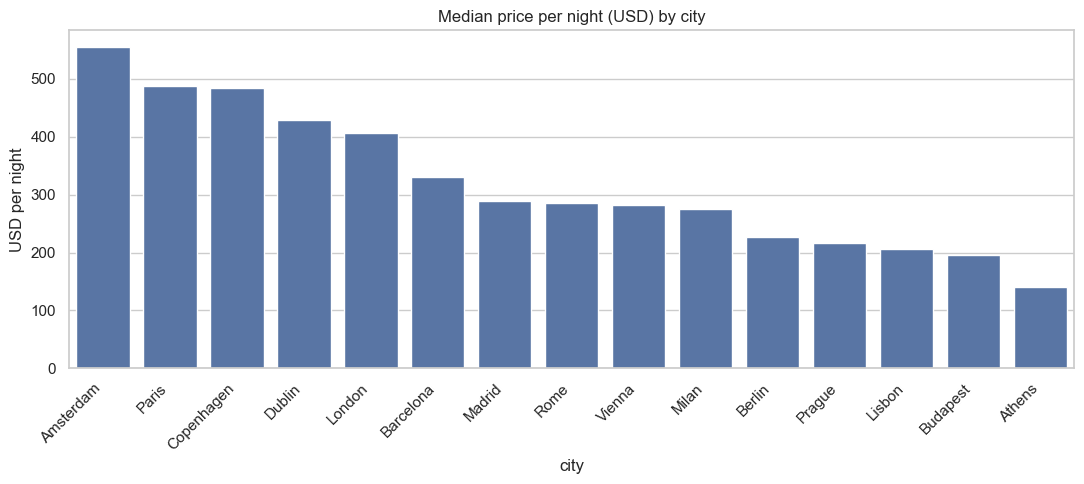

Most expensive city: Amsterdam (median $556 per night)
Cheapest city: Athens (median $141 per night)
Amsterdam is 3.9x more expensive than Athens


In [4]:
city_price = (df.groupby("city")
                .agg(listings=("listing_id", "count"),
                     median_per_night=("Price_per_night_USD", "median"),
                     mean_per_night=("Price_per_night_USD", "mean"),
                     median_5_nights=("Price_total_USD", "median"))
                .sort_values("median_per_night", ascending=False))
display(city_price)

plt.figure(figsize=(11, 5))
sns.barplot(data=city_price.reset_index(), x="city", y="median_per_night", order=city_price.index)
plt.xticks(rotation=45, ha="right")
plt.title("Median price per night (USD) by city")
plt.ylabel("USD per night")
plt.tight_layout()
plt.show()

top, bottom = city_price.index[0], city_price.index[-1]
print(f"Most expensive city: {top} (median ${city_price.loc[top, 'median_per_night']:,.0f} per night)")
print(f"Cheapest city: {bottom} (median ${city_price.loc[bottom, 'median_per_night']:,.0f} per night)")
print(f"{top} is {city_price.loc[top, 'median_per_night'] / city_price.loc[bottom, 'median_per_night']:.1f}x more expensive than {bottom}")

### Q2. Which countries are the most expensive? (Spain and Italy have 2 cities each)

In [5]:
country_price = (df.groupby("country")
                   .agg(listings=("listing_id", "count"),
                        median_per_night=("Price_per_night_USD", "median"))
                   .sort_values("median_per_night", ascending=False))
display(country_price)

,listings,median_per_night
country,,
Netherlands,46,555.67
France,42,487.24
Denmark,45,484.28
Ireland,43,428.88
United Kingdom,44,405.80
Spain,84,319.13
Italy,87,282.19
Austria,36,281.60
Germany,43,226.56


### Q3. How are prices distributed, and where are the outliers?

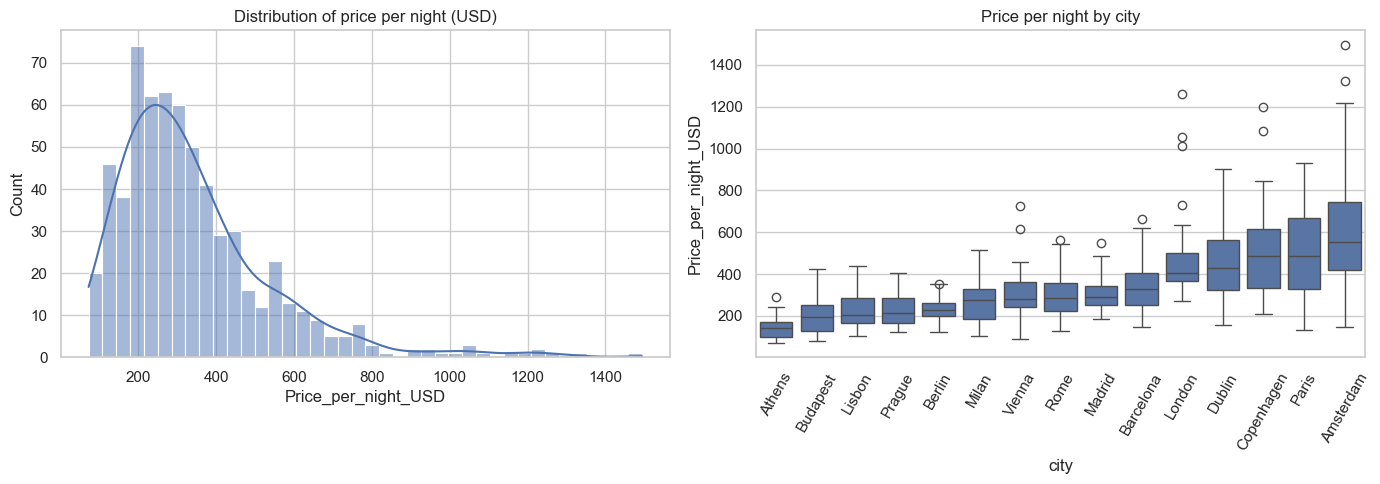

Skewness of price per night: 1.85 (above 1 means a long tail of expensive listings)
Outliers per city (IQR rule):
city
London        4
Copenhagen    2
Amsterdam     2
Vienna        2
Berlin        1
Barcelona     1
Athens        1
Rome          1
Madrid        1


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["Price_per_night_USD"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of price per night (USD)")
order = df.groupby("city")["Price_per_night_USD"].median().sort_values().index
sns.boxplot(data=df, x="city", y="Price_per_night_USD", order=order, ax=axes[1])
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_title("Price per night by city")
plt.tight_layout()
plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s > q3 + 1.5 * iqr) | (s < q1 - 1.5 * iqr)).sum())

outliers = df.groupby("city")["Price_per_night_USD"].apply(iqr_outliers).sort_values(ascending=False)
print(f"Skewness of price per night: {df['Price_per_night_USD'].skew():.2f} (above 1 means a long tail of expensive listings)")
print("Outliers per city (IQR rule):")
print(outliers[outliers > 0].to_string())

### Q4. Do Superhosts charge more and get better ratings?

In [7]:
sh = (df.groupby("Superhost")
        .agg(listings=("listing_id", "count"),
             median_per_night=("Price_per_night_USD", "median"),
             mean_rating=("Rating", "mean"),
             median_reviews=("Reviews", "median")))
sh.index = sh.index.map({0: "Not Superhost", 1: "Superhost"})
display(sh)

# Compare inside each city, so expensive cities do not distort the result
by_city = df.pivot_table(index="city", columns="Superhost", values="Price_per_night_USD", aggfunc="median")
by_city.columns = ["Not Superhost", "Superhost"]
by_city["superhost_premium_pct"] = ((by_city["Superhost"] / by_city["Not Superhost"] - 1) * 100).round(1)
display(by_city.sort_values("superhost_premium_pct", ascending=False))

a = df.loc[df["Superhost"] == 1, "Price_per_night_USD"]
b = df.loc[df["Superhost"] == 0, "Price_per_night_USD"]
p_price = stats.mannwhitneyu(a, b).pvalue
ra = df.loc[(df["Superhost"] == 1) & df["Rating"].notna(), "Rating"]
rb = df.loc[(df["Superhost"] == 0) & df["Rating"].notna(), "Rating"]
p_rating = stats.mannwhitneyu(ra, rb).pvalue
print(f"Price difference test p-value: {p_price:.4f} -> {'significant' if p_price < 0.05 else 'not significant'}")
print(f"Rating difference test p-value: {p_rating:.4f} -> {'significant' if p_rating < 0.05 else 'not significant'}")
print(f"Cities where Superhosts are more expensive: {(by_city['superhost_premium_pct'] > 0).sum()} of {len(by_city)}")

,listings,median_per_night,mean_rating,median_reviews
Superhost,,,,
Not Superhost,284,288.64,4.88,12.50
Superhost,352,294.03,4.93,104.00


,Not Superhost,Superhost,superhost_premium_pct
city,,,
Budapest,145.39,212.99,46.50
London,389.63,483.21,24.00
Vienna,249.50,308.48,23.60
Milan,238.15,286.89,20.50
Athens,127.21,148.83,17.00
Madrid,277.44,323.48,16.60
Dublin,380.90,442.21,16.10
Lisbon,193.91,224.51,15.80
Barcelona,322.53,364.58,13.00


Price difference test p-value: 0.7790 -> not significant
Rating difference test p-value: 0.3896 -> not significant
Cities where Superhosts are more expensive: 12 of 15


### Q5. Is Guest Favorite linked to higher ratings, more reviews, or higher prices?

,listings,median_per_night,mean_rating,median_reviews
is_fav,,,,
Not Guest Favorite,235,316.43,4.84,3.00
Guest Favorite,401,288.69,4.94,101.00


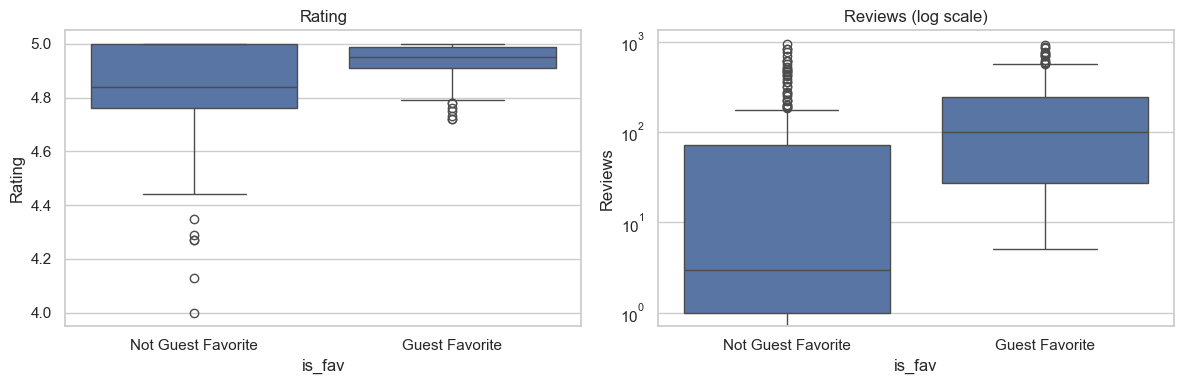

In [8]:
gf = (df.groupby("is_fav")
        .agg(listings=("listing_id", "count"),
             median_per_night=("Price_per_night_USD", "median"),
             mean_rating=("Rating", "mean"),
             median_reviews=("Reviews", "median")))
gf.index = gf.index.map({0: "Not Guest Favorite", 1: "Guest Favorite"})
display(gf)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="is_fav", y="Rating", ax=axes[0])
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Not Guest Favorite", "Guest Favorite"])
axes[0].set_title("Rating")
sns.boxplot(data=df, x="is_fav", y="Reviews", ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Not Guest Favorite", "Guest Favorite"])
axes[1].set_yscale("log")
axes[1].set_title("Reviews (log scale)")
plt.tight_layout()
plt.show()

### Q6. Does a higher price mean a better rating or more bookings (reviews)?

Price vs Rating  : Spearman rho = 0.09 (p = 0.0342)
Price vs Reviews : Spearman rho = -0.12 (p = 0.0034)
Rule of thumb: |rho| < 0.2 weak, 0.2-0.5 moderate, > 0.5 strong


,count,mean,median
price_tier,,,
Budget,140,4.90,4.92
Mid-range,142,4.90,4.94
Upper,139,4.90,4.94
Luxury,135,4.93,4.95


,count,mean,median
price_tier,,,
Budget,159,158.23,64.00
Mid-range,159,136.57,91.00
Upper,159,129.65,52.00
Luxury,159,102.27,24.00


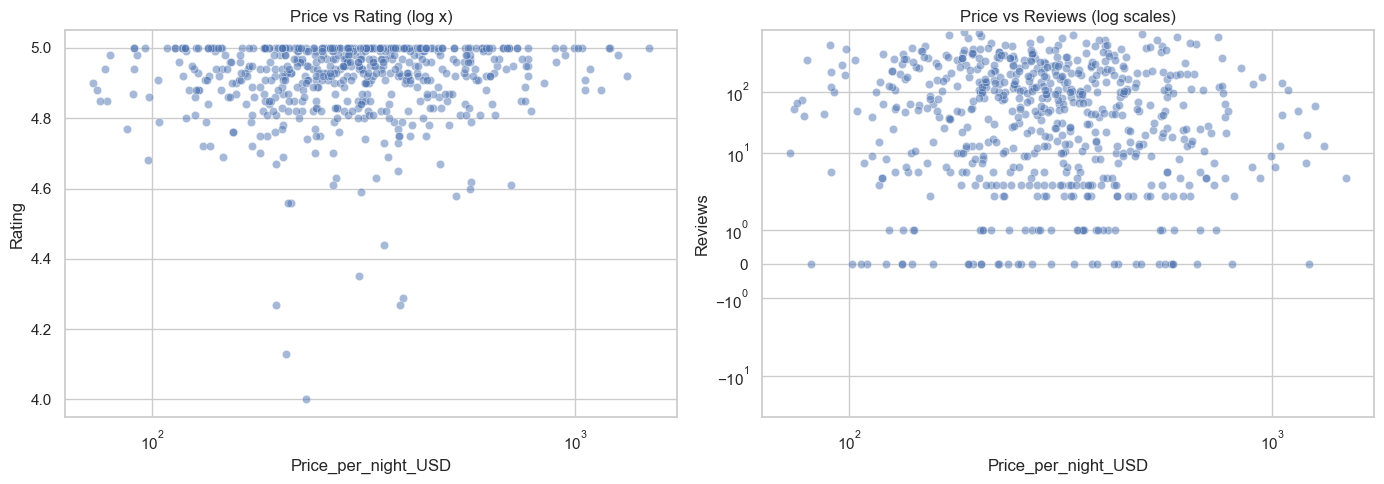

In [9]:
rated = df.dropna(subset=["Rating"])
rho_r, p_r = stats.spearmanr(rated["Price_per_night_USD"], rated["Rating"])
rho_v, p_v = stats.spearmanr(df["Price_per_night_USD"], df["Reviews"])
print(f"Price vs Rating  : Spearman rho = {rho_r:.2f} (p = {p_r:.4f})")
print(f"Price vs Reviews : Spearman rho = {rho_v:.2f} (p = {p_v:.4f})")
print("Rule of thumb: |rho| < 0.2 weak, 0.2-0.5 moderate, > 0.5 strong")

display(rated.groupby("price_tier", observed=True)["Rating"].agg(["count", "mean", "median"]))
display(df.groupby("price_tier", observed=True)["Reviews"].agg(["count", "mean", "median"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=rated, x="Price_per_night_USD", y="Rating", alpha=0.5, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_title("Price vs Rating (log x)")
sns.scatterplot(data=df, x="Price_per_night_USD", y="Reviews", alpha=0.5, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_yscale("symlog"); axes[1].set_title("Price vs Reviews (log scales)")
plt.tight_layout()
plt.show()

### Q7. How are ratings distributed, and which cities have the best-rated listings?

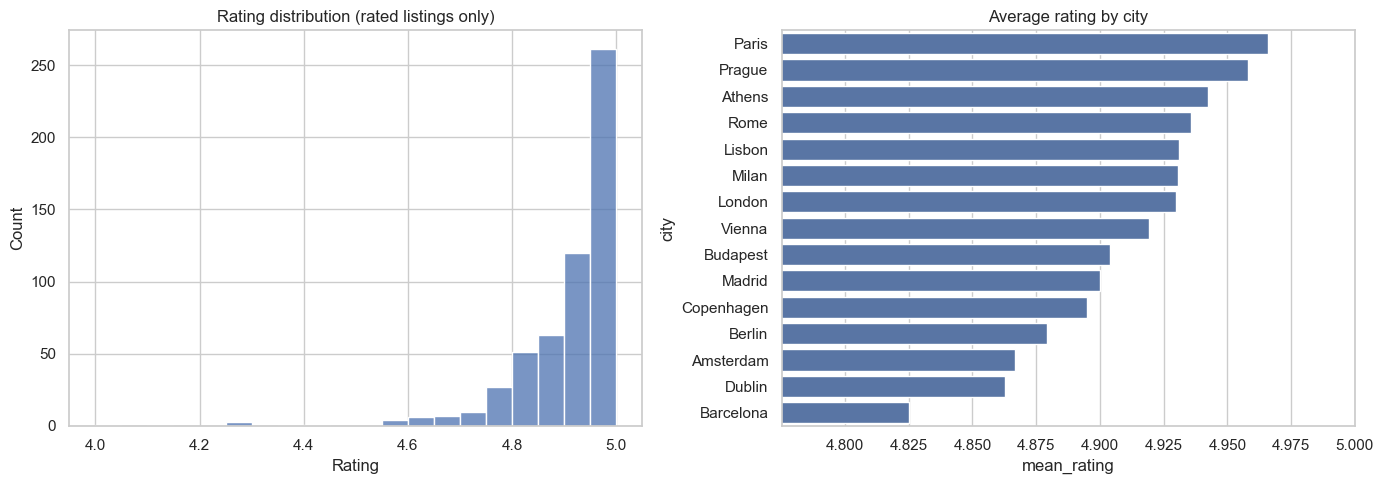

            mean_rating  rated_listings
city                                   
Paris              4.97              33
Prague             4.96              36
Athens             4.94              39
Rome               4.94              40
Lisbon             4.93              38
Milan              4.93              40
London             4.93              29
Vienna             4.92              34
Budapest           4.90              39
Madrid             4.90              32
Copenhagen         4.90              37
Berlin             4.88              37
Amsterdam          4.87              35
Dublin             4.86              43
Barcelona          4.83              44

rating_category
Excellent (>4.8)    488
Unrated              80
Good (4.5-4.8)       61
Fair (<=4.5)          7

Listings rated exactly 5.0: 138 (check their review counts, they are often low)
Median reviews of 5.0 listings: 6 | of other rated listings: 124


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(rated["Rating"], bins=20, ax=axes[0])
axes[0].set_title("Rating distribution (rated listings only)")
rating_city = (df.groupby("city")
                 .agg(mean_rating=("Rating", "mean"), rated_listings=("Rating", "count"))
                 .sort_values("mean_rating", ascending=False))
sns.barplot(data=rating_city.reset_index(), x="mean_rating", y="city", order=rating_city.index, ax=axes[1])
axes[1].set_xlim(rating_city["mean_rating"].min() - 0.05, 5)
axes[1].set_title("Average rating by city")
plt.tight_layout()
plt.show()

print(rating_city.round(2).to_string())
print()
print(df["rating_category"].value_counts().to_string())
print(f"\nListings rated exactly 5.0: {(df['Rating'] == 5.0).sum()} (check their review counts, they are often low)")
print(f"Median reviews of 5.0 listings: {df.loc[df['Rating'] == 5.0, 'Reviews'].median():.0f} | of other rated listings: {df.loc[(df['Rating'] < 5.0), 'Reviews'].median():.0f}")

### Q8. Which cities have more Superhosts and Guest Favorites?

,superhost_pct,guest_favorite_pct
city,,
Prague,76.90,82.10
Athens,74.40,81.40
Dublin,67.40,58.10
Budapest,64.30,76.20
Vienna,61.10,66.70
Barcelona,59.60,63.80
Milan,58.70,63.00
Rome,58.50,75.60
Lisbon,52.40,78.60


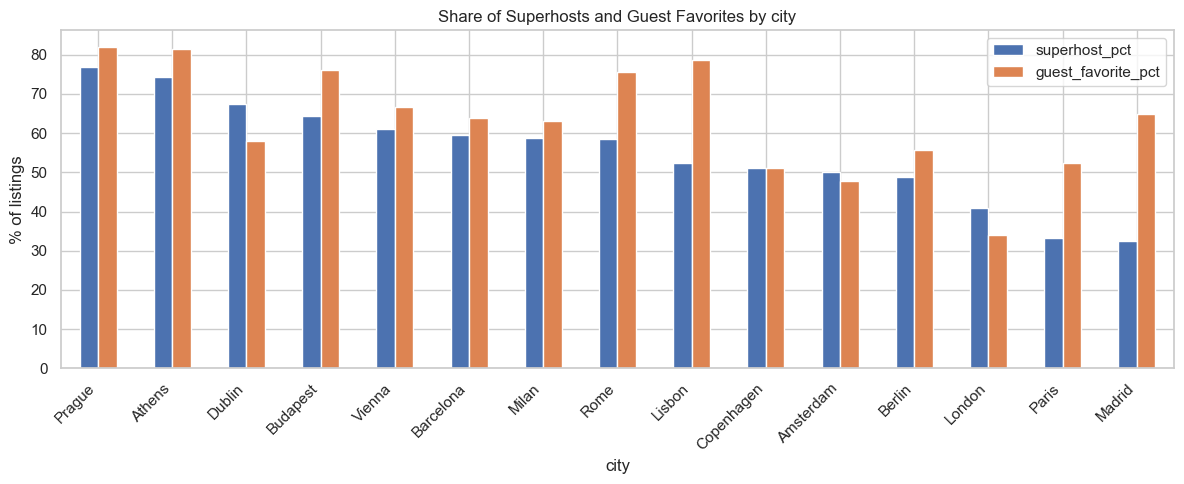

In [11]:
share = (df.groupby("city")
           .agg(superhost_pct=("Superhost", "mean"), guest_favorite_pct=("is_fav", "mean"))
           .mul(100).round(1)
           .sort_values("superhost_pct", ascending=False))
display(share)

share.plot(kind="bar", figsize=(12, 5))
plt.ylabel("% of listings")
plt.title("Share of Superhosts and Guest Favorites by city")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Q9. Which cities have the newest and least established market (few reviews, unrated)?

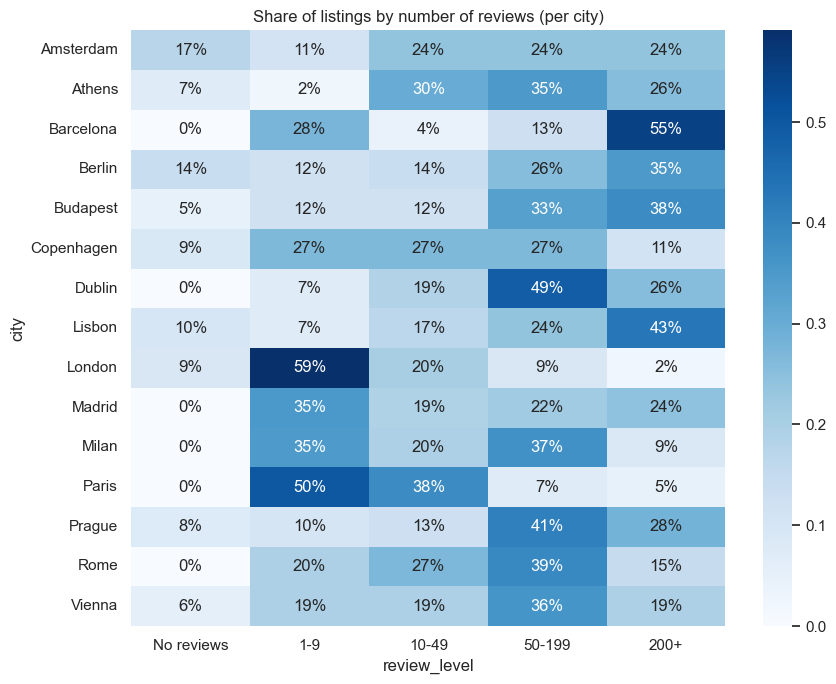

% of listings with no rating yet, by city:
city
London       34.10
Amsterdam    23.90
Paris        21.40
Copenhagen   17.80
Berlin       14.00
Madrid       13.50
Milan        13.00
Lisbon        9.50
Athens        9.30
Prague        7.70
Budapest      7.10
Barcelona     6.40
Vienna        5.60
Rome          2.40
Dublin        0.00


In [12]:
ct = pd.crosstab(df["city"], df["review_level"], normalize="index")
plt.figure(figsize=(9, 7))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues")
plt.title("Share of listings by number of reviews (per city)")
plt.tight_layout()
plt.show()

new_share = (df.groupby("city")["has_rating"].apply(lambda s: (1 - s.mean()) * 100)
               .round(1).sort_values(ascending=False))
print("% of listings with no rating yet, by city:")
print(new_share.to_string())

### Q10. Which host segment (Superhost / Guest Favorite) performs best?

,listings,median_per_night,mean_rating,median_reviews,share_pct
host_segment,,,,,
Superhost + Guest Favorite,276,291.58,4.94,116.50,43.40
Standard,159,316.43,4.82,3.00,25.00
Guest Favorite only,125,277.68,4.93,50.00,19.70
Superhost only,76,317.06,4.86,12.00,11.90


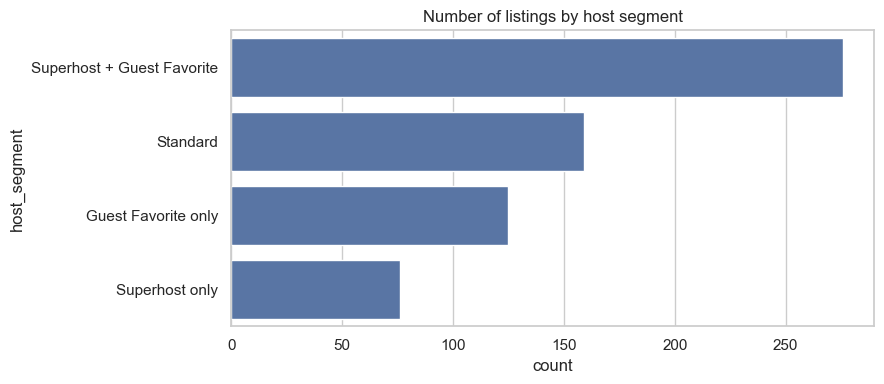

In [13]:
segment_summary = (df.groupby("host_segment")
                     .agg(listings=("listing_id", "count"),
                          median_per_night=("Price_per_night_USD", "median"),
                          mean_rating=("Rating", "mean"),
                          median_reviews=("Reviews", "median"))
                     .sort_values("listings", ascending=False))
segment_summary["share_pct"] = (segment_summary["listings"] / len(df) * 100).round(1)
display(segment_summary)

plt.figure(figsize=(9, 4))
sns.countplot(data=df, y="host_segment", order=segment_summary.index)
plt.title("Number of listings by host segment")
plt.tight_layout()
plt.show()

### Q11. Where are the best-value listings? (high rating, many reviews, cheaper than the city median)

In [14]:
cols = ["Name", "city", "Price_per_night_USD", "price_vs_city_median_pct", "Rating", "Reviews", "host_segment", "URL"]

best_value = (df[(df["Rating"] >= 4.9) & (df["Reviews"] >= 50) & (df["price_vs_city_median_pct"] <= -10)]
                .sort_values(["Rating", "Reviews"], ascending=[False, False])
                .head(10)[cols])
print("Top 10 best-value listings (rating >= 4.9, 50+ reviews, 10%+ cheaper than city median):")
display(best_value)

cheap_good = (df[(df["Rating"] >= 4.8) & (df["Reviews"] >= 20)]
                .sort_values("Price_per_night_USD")
                .groupby("city").head(1)
                .sort_values("Price_per_night_USD")[cols])
print("Cheapest well-reviewed listing in each city (rating >= 4.8, 20+ reviews):")
display(cheap_good)

Top 10 best-value listings (rating >= 4.9, 50+ reviews, 10%+ cheaper than city median):


,Name,city,Price_per_night_USD,price_vs_city_median_pct,Rating,Reviews,host_segment,URL
53,"Stylish Sunny New 2 Bedroom, Prime Central Athens",Athens,96.03,-31.80,5.00,268,Superhost + Guest Favorite,https://www.airbnb.com/rooms/36191151?search_m...
63,Wonderful Central Athens 2 Bedroom 2 Bath Slee...,Athens,90.70,-35.60,5.00,120,Superhost + Guest Favorite,https://www.airbnb.com/rooms/48600124?search_m...
334,NEW Luxury flat 2BR Paris 14th / Porte de Vers...,Paris,294.16,-39.60,5.00,80,Guest Favorite only,https://www.airbnb.com/rooms/14732040088181997...
50,Vasilis Home. Central Athens. Under Acropolis,Athens,120.19,-14.60,4.99,412,Superhost + Guest Favorite,https://www.airbnb.com/rooms/27297704?search_m...
34,Luxury Island with Boat and Sauna near Amsterdam,Amsterdam,473.71,-14.80,4.99,118,Superhost + Guest Favorite,https://www.airbnb.com/rooms/12730304666618045...
383,Domus Diamond - Luxury Apartment,Rome,230.68,-19.00,4.99,89,Superhost + Guest Favorite,https://www.airbnb.com/rooms/14399709788385314...
42,Windmill close to Amsterdam!!,Amsterdam,311.30,-44.00,4.98,574,Guest Favorite only,https://www.airbnb.com/rooms/2107131?search_mo...
228,Historic Lisbon Tile House,Lisbon,149.02,-27.40,4.98,452,Superhost + Guest Favorite,https://www.airbnb.com/rooms/18319478?search_m...
181,3. Cozy apartment 5th floor,Budapest,79.76,-59.20,4.98,325,Superhost + Guest Favorite,https://www.airbnb.com/rooms/88260322355806020...
139,somewhere else - Stylish & Cozy City Apartment,Berlin,201.12,-11.20,4.98,233,Guest Favorite only,https://www.airbnb.com/rooms/15660868?search_m...


Cheapest well-reviewed listing in each city (rating >= 4.8, 20+ reviews):


,Name,city,Price_per_night_USD,price_vs_city_median_pct,Rating,Reviews,host_segment,URL
57,Athens Museum Apartment,Athens,74.03,-47.40,4.88,52,Superhost + Guest Favorite,https://www.airbnb.com/rooms/12077508452795144...
181,3. Cozy apartment 5th floor,Budapest,79.76,-59.20,4.98,325,Superhost + Guest Favorite,https://www.airbnb.com/rooms/88260322355806020...
509,"Cozy Apartment with Free Parking, AC and Balcony",Prague,124.16,-42.50,4.95,124,Superhost + Guest Favorite,https://www.airbnb.com/rooms/94577498731374750...
256,Deluxe apartment by the sea,Lisbon,126.00,-38.60,4.94,213,Superhost + Guest Favorite,https://www.airbnb.com/rooms/51100406?search_m...
352,TrasteveRhome - House of Fashion,Rome,126.49,-55.60,4.86,118,Superhost + Guest Favorite,https://www.airbnb.com/rooms/12236673582299323...
471,Glamour Apartment in Milan,Milan,127.39,-53.70,4.88,338,Superhost + Guest Favorite,https://www.airbnb.com/rooms/60424997250563361...
23,Family house with private parking in Almere Haven,Amsterdam,146.11,-73.70,4.94,242,Guest Favorite only,https://www.airbnb.com/rooms/18478409?search_m...
178,Sunny Terrace | Free Parking | Quiet & Near City,Berlin,161.52,-28.70,4.98,49,Superhost + Guest Favorite,https://www.airbnb.com/rooms/15020201450013550...
430,Modern & Comfortable Apartment La Latina/Plz M...,Madrid,184.88,-36.00,4.85,347,Superhost + Guest Favorite,https://www.airbnb.com/rooms/52504852?search_m...
392,"Cozy Corner perfect for 4-6 free parking, hip ...",Vienna,192.88,-31.50,4.82,228,Superhost only,https://www.airbnb.com/rooms/12739851892461028...


### Q12. How are the numeric variables related to each other?

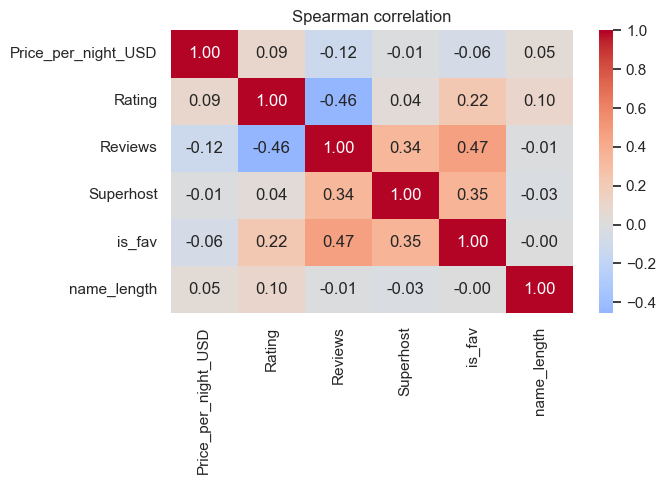

In [15]:
num_cols = ["Price_per_night_USD", "Rating", "Reviews", "Superhost", "is_fav", "name_length"]
corr = df[num_cols].corr(method="spearman")
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation")
plt.tight_layout()
plt.show()

## 4. New tables for the next stage (Data Warehouse)

These tables are saved in `data/processed/eda_tables/`:
- `Airbnb_Enriched.csv`: the cleaned data plus all new columns (this will be the base of the fact table).
- `dim_city.csv`: one row per city with `city_id` and `country`.
- `city_summary.csv`: one row per city with the main metrics.
- `host_segment_summary.csv` and `price_tier_summary.csv`: summary tables.

In [16]:
EDA_TABLES_DIR.mkdir(parents=True, exist_ok=True)

dim_city = (df[["city", "country"]].drop_duplicates().sort_values("city").reset_index(drop=True))
dim_city.insert(0, "city_id", dim_city.index + 1)

city_summary = (df.groupby(["city", "country"])
                  .agg(listings=("listing_id", "count"),
                       median_price_per_night_usd=("Price_per_night_USD", "median"),
                       mean_price_per_night_usd=("Price_per_night_USD", "mean"),
                       mean_rating=("Rating", "mean"),
                       median_reviews=("Reviews", "median"),
                       superhost_pct=("Superhost", lambda s: s.mean() * 100),
                       guest_favorite_pct=("is_fav", lambda s: s.mean() * 100),
                       unrated_pct=("has_rating", lambda s: (1 - s.mean()) * 100))
                  .round(2).reset_index()
                  .merge(dim_city[["city", "city_id"]], on="city")
                  .sort_values("median_price_per_night_usd", ascending=False))

price_tier_summary = (df.groupby("price_tier", observed=True)
                        .agg(listings=("listing_id", "count"),
                             min_price=("Price_per_night_USD", "min"),
                             max_price=("Price_per_night_USD", "max"),
                             mean_rating=("Rating", "mean"),
                             median_reviews=("Reviews", "median"))
                        .round(2).reset_index())

df.to_csv(EDA_TABLES_DIR / "Airbnb_Enriched.csv", index=False)
dim_city.to_csv(EDA_TABLES_DIR / "dim_city.csv", index=False)
city_summary.to_csv(EDA_TABLES_DIR / "city_summary.csv", index=False)
segment_summary.reset_index().to_csv(EDA_TABLES_DIR / "host_segment_summary.csv", index=False)
price_tier_summary.to_csv(EDA_TABLES_DIR / "price_tier_summary.csv", index=False)

display(city_summary)
display(price_tier_summary)

,city,country,listings,median_price_per_night_usd,mean_price_per_night_usd,mean_rating,median_reviews,superhost_pct,guest_favorite_pct,unrated_pct,city_id
0,Amsterdam,Netherlands,46,555.67,617.82,4.87,46.50,50.00,47.83,23.91,1
11,Paris,France,42,487.24,496.87,4.97,9.50,33.33,52.38,21.43,12
5,Copenhagen,Denmark,45,484.28,499.05,4.90,25.00,51.11,51.11,17.78,6
6,Dublin,Ireland,43,428.88,456.56,4.86,108.00,67.44,58.14,0.00,7
8,London,United Kingdom,44,405.80,474.87,4.93,4.00,40.91,34.09,34.09,9
2,Barcelona,Spain,47,330.72,348.17,4.83,226.00,59.57,63.83,6.38,3
9,Madrid,Spain,37,288.69,302.85,4.90,31.00,32.43,64.86,13.51,10
13,Rome,Italy,41,284.71,290.64,4.94,53.00,58.54,75.61,2.44,14
14,Vienna,Austria,36,281.60,305.70,4.92,84.00,61.11,66.67,5.56,15
10,Milan,Italy,46,274.97,269.64,4.93,47.50,58.70,63.04,13.04,11


,price_tier,listings,min_price,max_price,mean_rating,median_reviews
0,Budget,159,72.57,205.67,4.90,64.00
1,Mid-range,159,205.72,292.27,4.90,91.00
2,Upper,159,292.64,422.40,4.90,52.00
3,Luxury,159,422.59,"1,494.30",4.93,24.00


## 5. Key findings (generated from the data)

In [17]:
top3 = city_price.head(3).index.tolist()
low3 = city_price.tail(3).index.tolist()
print(f"1. Most expensive cities: {', '.join(top3)}. Cheapest: {', '.join(low3)}.")
print(f"2. Median price: ${df['Price_per_night_USD'].median():,.0f} per night (${df['Price_total_USD'].median():,.0f} for 5 nights, all fees included).")
print(f"3. {df['Superhost'].mean() * 100:.0f}% of listings are Superhost, {df['is_fav'].mean() * 100:.0f}% are Guest Favorite.")
print(f"4. Superhost vs non-Superhost median price: ${a.median():,.0f} vs ${b.median():,.0f} (p = {p_price:.3f}).")
print(f"5. Price vs rating correlation: {rho_r:.2f}; price vs reviews correlation: {rho_v:.2f}.")
print(f"6. {100 - df['has_rating'].mean() * 100:.0f}% of listings have no rating yet; the city with the most is {new_share.index[0]} ({new_share.iloc[0]:.0f}%).")
print(f"7. Average rating is {df['Rating'].mean():.2f}, so ratings are compressed near the top and do not separate listings well.")

1. Most expensive cities: Amsterdam, Paris, Copenhagen. Cheapest: Lisbon, Budapest, Athens.
2. Median price: $292 per night ($1,462 for 5 nights, all fees included).
3. 55% of listings are Superhost, 63% are Guest Favorite.
4. Superhost vs non-Superhost median price: $294 vs $289 (p = 0.779).
5. Price vs rating correlation: 0.09; price vs reviews correlation: -0.12.
6. 13% of listings have no rating yet; the city with the most is London (34%).
7. Average rating is 4.91, so ratings are compressed near the top and do not separate listings well.
